Link de GoogleDrive HERE

# Online Shoppers Purchasing Intention Dataset

In [338]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
from math import sqrt
from scipy import stats
from scipy.stats import binom
from scipy.stats import poisson
from scipy.stats import geom
from scipy.stats import ttest_ind
from scipy.stats import norm
from scipy.stats import shapiro, norm, mannwhitneyu, wilcoxon
from scipy.stats import chi2
from scipy.stats import chi2_contingency
from scipy.stats import spearmanr

## Read Dataset

In [5]:
#Read the document and the head of the data 
df=pd.read_csv("online_shoppers_intention.csv")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [6]:
#To know how many rows and columns
df.shape

(12330, 18)

Code Explanation:
- read_csv: to read the dataset.
- head(): to know the first 5 rows of the dataset and see which kind of data contains.
- shape: to know the total number of rows and features.

Interpretation:
The first exploratory phase of the online_shoppers_intention dataset informed a structure of 1.2330 rows and 18 features. The dataset contains continuous (e.g. BounceRates), discrete (e.g. ProductRelated) and categorical (e.g. VisitorType) variables.	

In [8]:
#To know the name of the columns and know which one could I delete it
df.columns

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='str')

In [9]:
#To know the type of the data in the dataset / str = text / float64 = decimel / int = #s / bool = booleano
df.dtypes

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

Code Explanation:
- columns: to see the column names.
- dtypes: to know what kind of data is in the dataset.

Interpretation:
The data-type inspection confirms that 10 quantitative metrics are stored as int64 and float64, and 8 categorical attributes. While Month, VisitorType, Weekend, and Revenue are explicitly stored as string and boolean types, OperatingSystems, Browser, Region, and TrafficType are encoded as int64 integers.

## Clean data

In [12]:
#Check null values
df.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [13]:
#Convert NAN per columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [14]:
categ_columns = ['OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Month']

df[categ_columns] = df[categ_columns].astype("category")

In [15]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000


Code Explanation:
- isnull().sum(): to know how many null values the dataset contains
- info(): to verify that every column (categorical or numerical) contains non-null values.
- categ_columns: to be sure that all the categorical columns remain categorical and not that the system counts them as numerical by mistake.
- describe(): to see all the numerical columns and their different measures.

Interpretation: 
The dataset does not contain any null values. As the dataset has categorical and numerical data and the assessment required both categories, the dataset needs to keep the categorical data as categorical; that is why the categ_columns helps to select the categorical features ('OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Month') as categorical.

Although several numerical attributes exhibit a high frequency of zero values such as (Informational, Administrative, PageValues, and SpecialDay), domain documentation confirms that these represent structural (true) zeros rather than missing data (Sakar and Komiya, 2018). Specifically, a zero in page-count and duration metrics indicates that the user did not visit that specific section during the session; a zero in BounceRates reflects multi-page engagement without immediate exit; a zero in PageValues denotes sessions that did not lead to a financial transaction; and a zero in SpecialDay indicates navigation on a regular calendar date outside promotional windows. For that reason, all zero values were retained to preserve the authentic behavioural distribution of the user sessions.

## EDA

### Mean, Median and Mode

In [19]:
#Mean, Median and Mode of every column (conditional)
cols = df.columns.tolist()
for i in cols:
    if df[i].dtype in ['category', 'bool']:
        continue
    else:
        mean = df[i].mean()
        median = df[i].median()
        mode = df[i].mode() [0]
        print(f"Mean of {i}: {mean}| Median of {i}: {median}| Mode of {i}: {mode}")

Mean of Administrative: 2.3151662611516626| Median of Administrative: 1.0| Mode of Administrative: 0
Mean of Administrative_Duration: 80.81861053933592| Median of Administrative_Duration: 7.5| Mode of Administrative_Duration: 0.0
Mean of Informational: 0.5035685320356853| Median of Informational: 0.0| Mode of Informational: 0
Mean of Informational_Duration: 34.47239792772304| Median of Informational_Duration: 0.0| Mode of Informational_Duration: 0.0
Mean of ProductRelated: 31.731467964314678| Median of ProductRelated: 18.0| Mode of ProductRelated: 1
Mean of ProductRelated_Duration: 1194.7462199688268| Median of ProductRelated_Duration: 598.9369047499999| Mode of ProductRelated_Duration: 0.0
Mean of BounceRates: 0.02219138047072182| Median of BounceRates: 0.0031124675| Mode of BounceRates: 0.0
Mean of ExitRates: 0.04307279776650446| Median of ExitRates: 0.0251564025| Mode of ExitRates: 0.2
Mean of PageValues: 5.889257862693593| Median of PageValues: 0.0| Mode of PageValues: 0.0
Mean of 

### Minimum / Maximum Value and Range

In [21]:
#Minimum/ Maximum and Range value on the loop
for i in cols:
    if df[i].dtype in ['category', 'bool']:
        continue
    else:
        minimum = df[i].min()
        maximum = df[i].max()
        range = df[i].max() - df[i].min()
        print(f"Minimum of {i}: {minimum} | Maximum of {i}: {maximum} | Range of {i}: {range}")

Minimum of Administrative: 0 | Maximum of Administrative: 27 | Range of Administrative: 27
Minimum of Administrative_Duration: 0.0 | Maximum of Administrative_Duration: 3398.75 | Range of Administrative_Duration: 3398.75
Minimum of Informational: 0 | Maximum of Informational: 24 | Range of Informational: 24
Minimum of Informational_Duration: 0.0 | Maximum of Informational_Duration: 2549.375 | Range of Informational_Duration: 2549.375
Minimum of ProductRelated: 0 | Maximum of ProductRelated: 705 | Range of ProductRelated: 705
Minimum of ProductRelated_Duration: 0.0 | Maximum of ProductRelated_Duration: 63973.52223 | Range of ProductRelated_Duration: 63973.52223
Minimum of BounceRates: 0.0 | Maximum of BounceRates: 0.2 | Range of BounceRates: 0.2
Minimum of ExitRates: 0.0 | Maximum of ExitRates: 0.2 | Range of ExitRates: 0.2
Minimum of PageValues: 0.0 | Maximum of PageValues: 361.7637419 | Range of PageValues: 361.7637419
Minimum of SpecialDay: 0.0 | Maximum of SpecialDay: 1.0 | Range of

### Variance and Std

In [23]:
#Variance and Std value on the loop
for i in cols:
    if df[i].dtype in ['category', 'bool']:
        continue
    else:
        variance = df[i].var()
        standard_deviation = df[i].std()
        print(f"Variance of {i}: {variance} | Standard Deviation of {i}: {standard_deviation}")

Variance of Administrative: 11.03424964791667 | Standard Deviation of Administrative: 3.3217841061569113
Variance of Administrative_Duration: 31250.852838061757 | Standard Deviation of Administrative_Duration: 176.77910747048634
Variance of Informational: 1.6132973464669016 | Standard Deviation of Informational: 1.270156425983391
Variance of Informational_Duration: 19810.363880346566 | Standard Deviation of Informational_Duration: 140.74929442219795
Variance of ProductRelated: 1978.0703942274188 | Standard Deviation of ProductRelated: 44.47550330493652
Variance of ProductRelated_Duration: 3662130.143344541 | Standard Deviation of ProductRelated_Duration: 1913.6692878720035
Variance of BounceRates: 0.002351117351587493 | Standard Deviation of BounceRates: 0.048488321806260656
Variance of ExitRates: 0.0023616237535680987 | Standard Deviation of ExitRates: 0.048596540551443565
Variance of PageValues: 344.78683805812955 | Standard Deviation of PageValues: 18.568436607806525
Variance of Spe

## IQR

In [25]:
for i in cols:
    if df[i].dtype in ['category', 'bool']:
        continue
    else:
        Q3 = df[i].quantile(0.75)
        Q1 = df[i].quantile(0.25)
        R = Q3  - Q1
        print(f"Quantile 3 of {i}: {Q3} | Quantile 1 of {i}: {Q1} | Interquantile Range of {i}: {R}")

Quantile 3 of Administrative: 4.0 | Quantile 1 of Administrative: 0.0 | Interquantile Range of Administrative: 4.0
Quantile 3 of Administrative_Duration: 93.25625 | Quantile 1 of Administrative_Duration: 0.0 | Interquantile Range of Administrative_Duration: 93.25625
Quantile 3 of Informational: 0.0 | Quantile 1 of Informational: 0.0 | Interquantile Range of Informational: 0.0
Quantile 3 of Informational_Duration: 0.0 | Quantile 1 of Informational_Duration: 0.0 | Interquantile Range of Informational_Duration: 0.0
Quantile 3 of ProductRelated: 38.0 | Quantile 1 of ProductRelated: 7.0 | Interquantile Range of ProductRelated: 31.0
Quantile 3 of ProductRelated_Duration: 1464.1572135000001 | Quantile 1 of ProductRelated_Duration: 184.1375 | Interquantile Range of ProductRelated_Duration: 1280.0197135
Quantile 3 of BounceRates: 0.016812558499999998 | Quantile 1 of BounceRates: 0.0 | Interquantile Range of BounceRates: 0.016812558499999998
Quantile 3 of ExitRates: 0.05 | Quantile 1 of ExitRate

Code Explanation:
- for i in cols:
    if df[i].dtype in ['category', 'bool']:
        continue
    else: This loop is used in all the differents measures, then the first line explains that every column of the dataset is taken and "i" a temporaryly variable that is using in every columns, the second line defines if that columns in specyfic is categorical o numerical o bool, third line "continue" is a skipping in case that the second line is true, fourth line "else:..." is the moment when python manangement the funtion requested.

Interpretation (3 more important features): 
- ProductRelated_Duration: the mean is 1,194.75 s, almost double the median of 598.94 seconds, and the mode is 0.0, with a range of 63,973.52 s and the std is 1,913.67 s, but the IQR is 1,280.02 s. A big different between mean and median is a probablitity to has a right-skewness.
- BounceRates: the mean is 0.0222 s, the median is 0.0485 seconds, and the mode is 0.0, with a range between 0.0 and 0.20 s, and the std is 0.0485 s, but the IQR is 0.0168 s.
- PagesValues: the mean is 5.89 s, the median and the mode are 0.0, with a range between 0.0 and 361,76 s, and the std is 18.57 s, but the IQR is 0.0 s.

### Plot the distribution

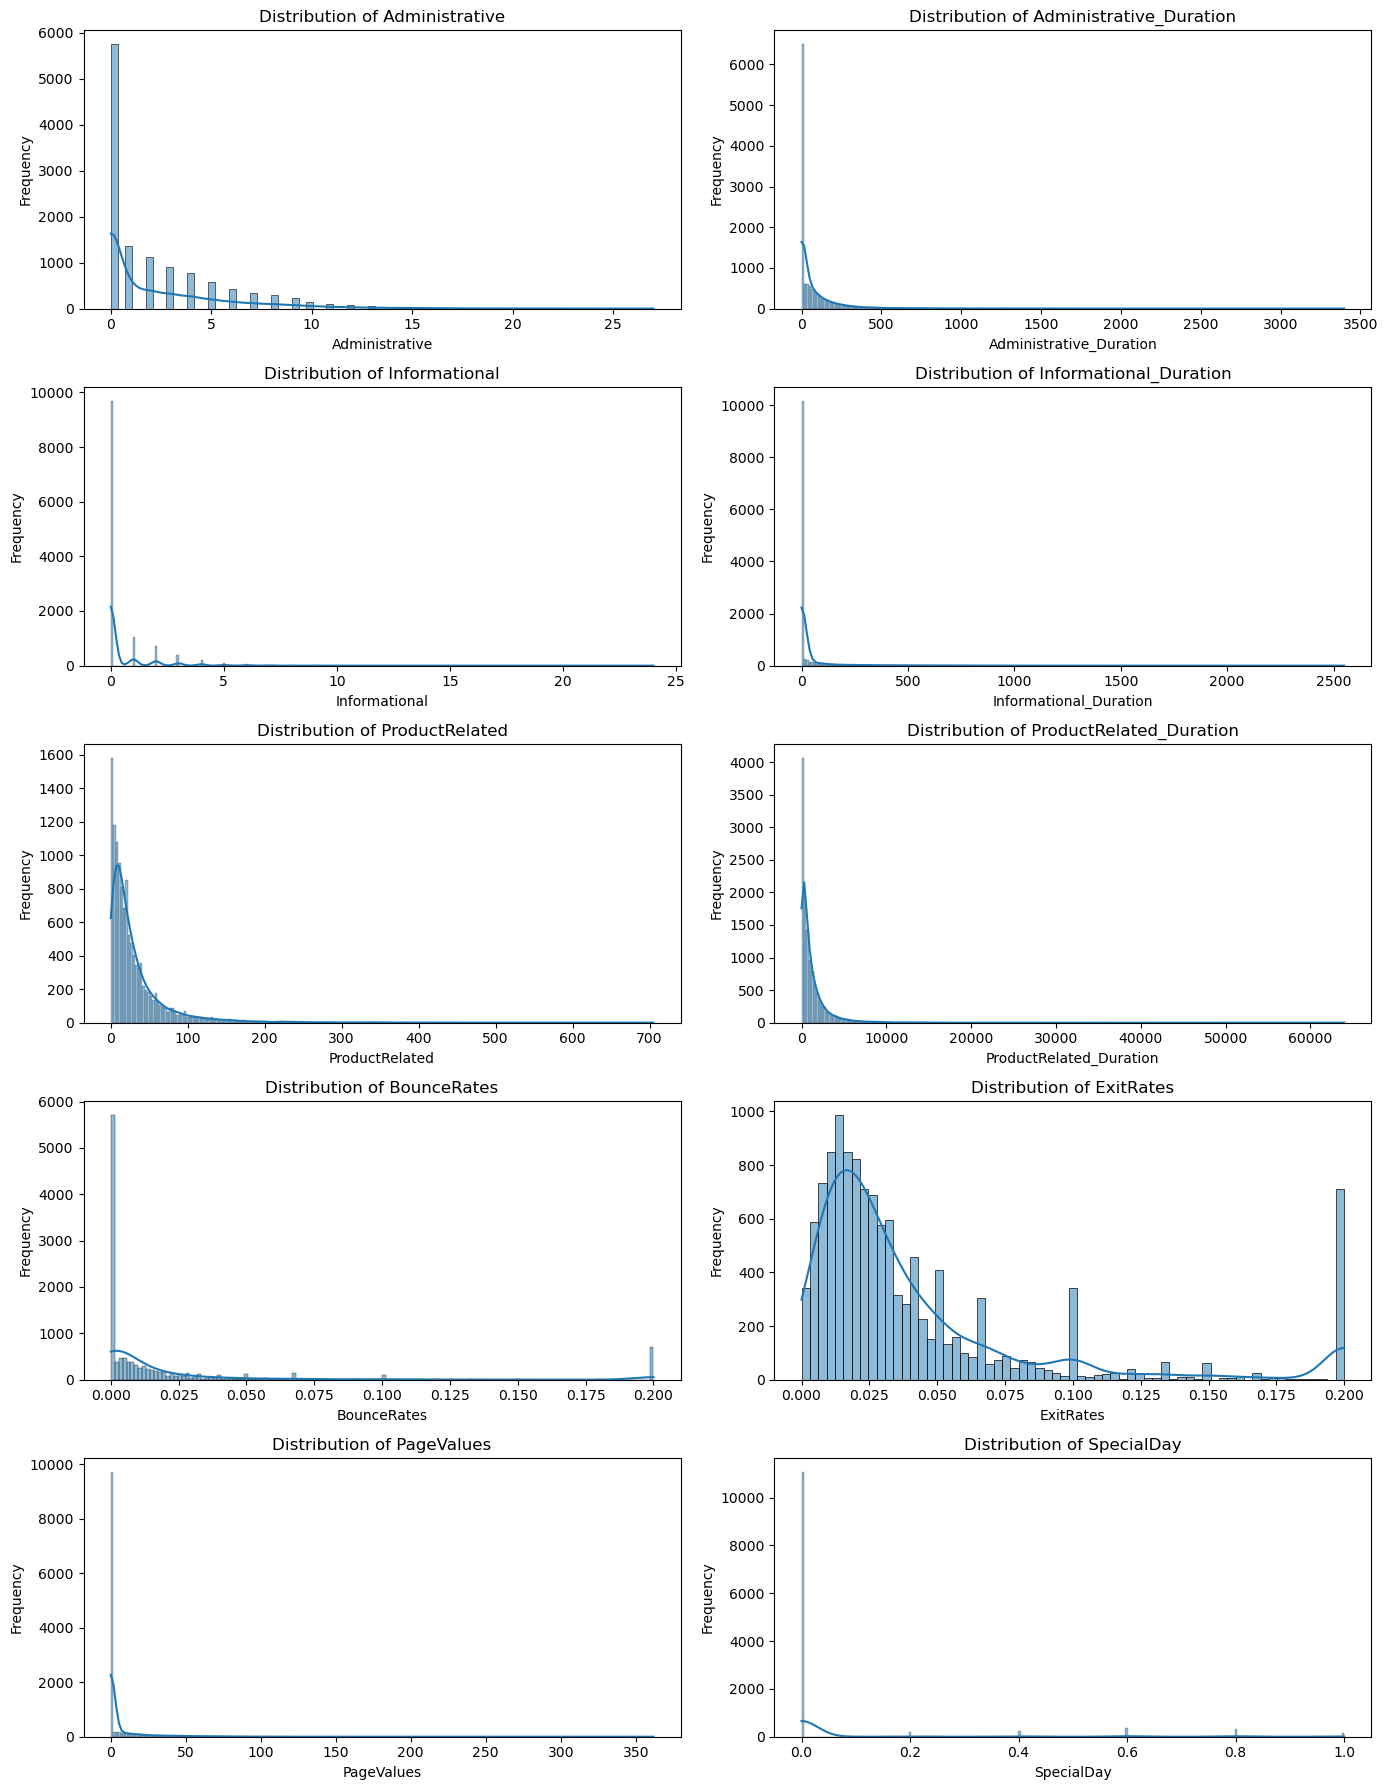

In [28]:
# Plot the distribution columns
columns_1 = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration", "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
fig, axes = plt.subplots(5,2, figsize=(14,18))
axes = axes.flatten()

for index, cols in enumerate (columns_1):
    sns.histplot(df[cols], kde=True, ax=axes[index])
    axes[index].set_title(f'Distribution of {cols}')
    axes[index].set_xlabel(cols)
    axes[index].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Draw boxplot

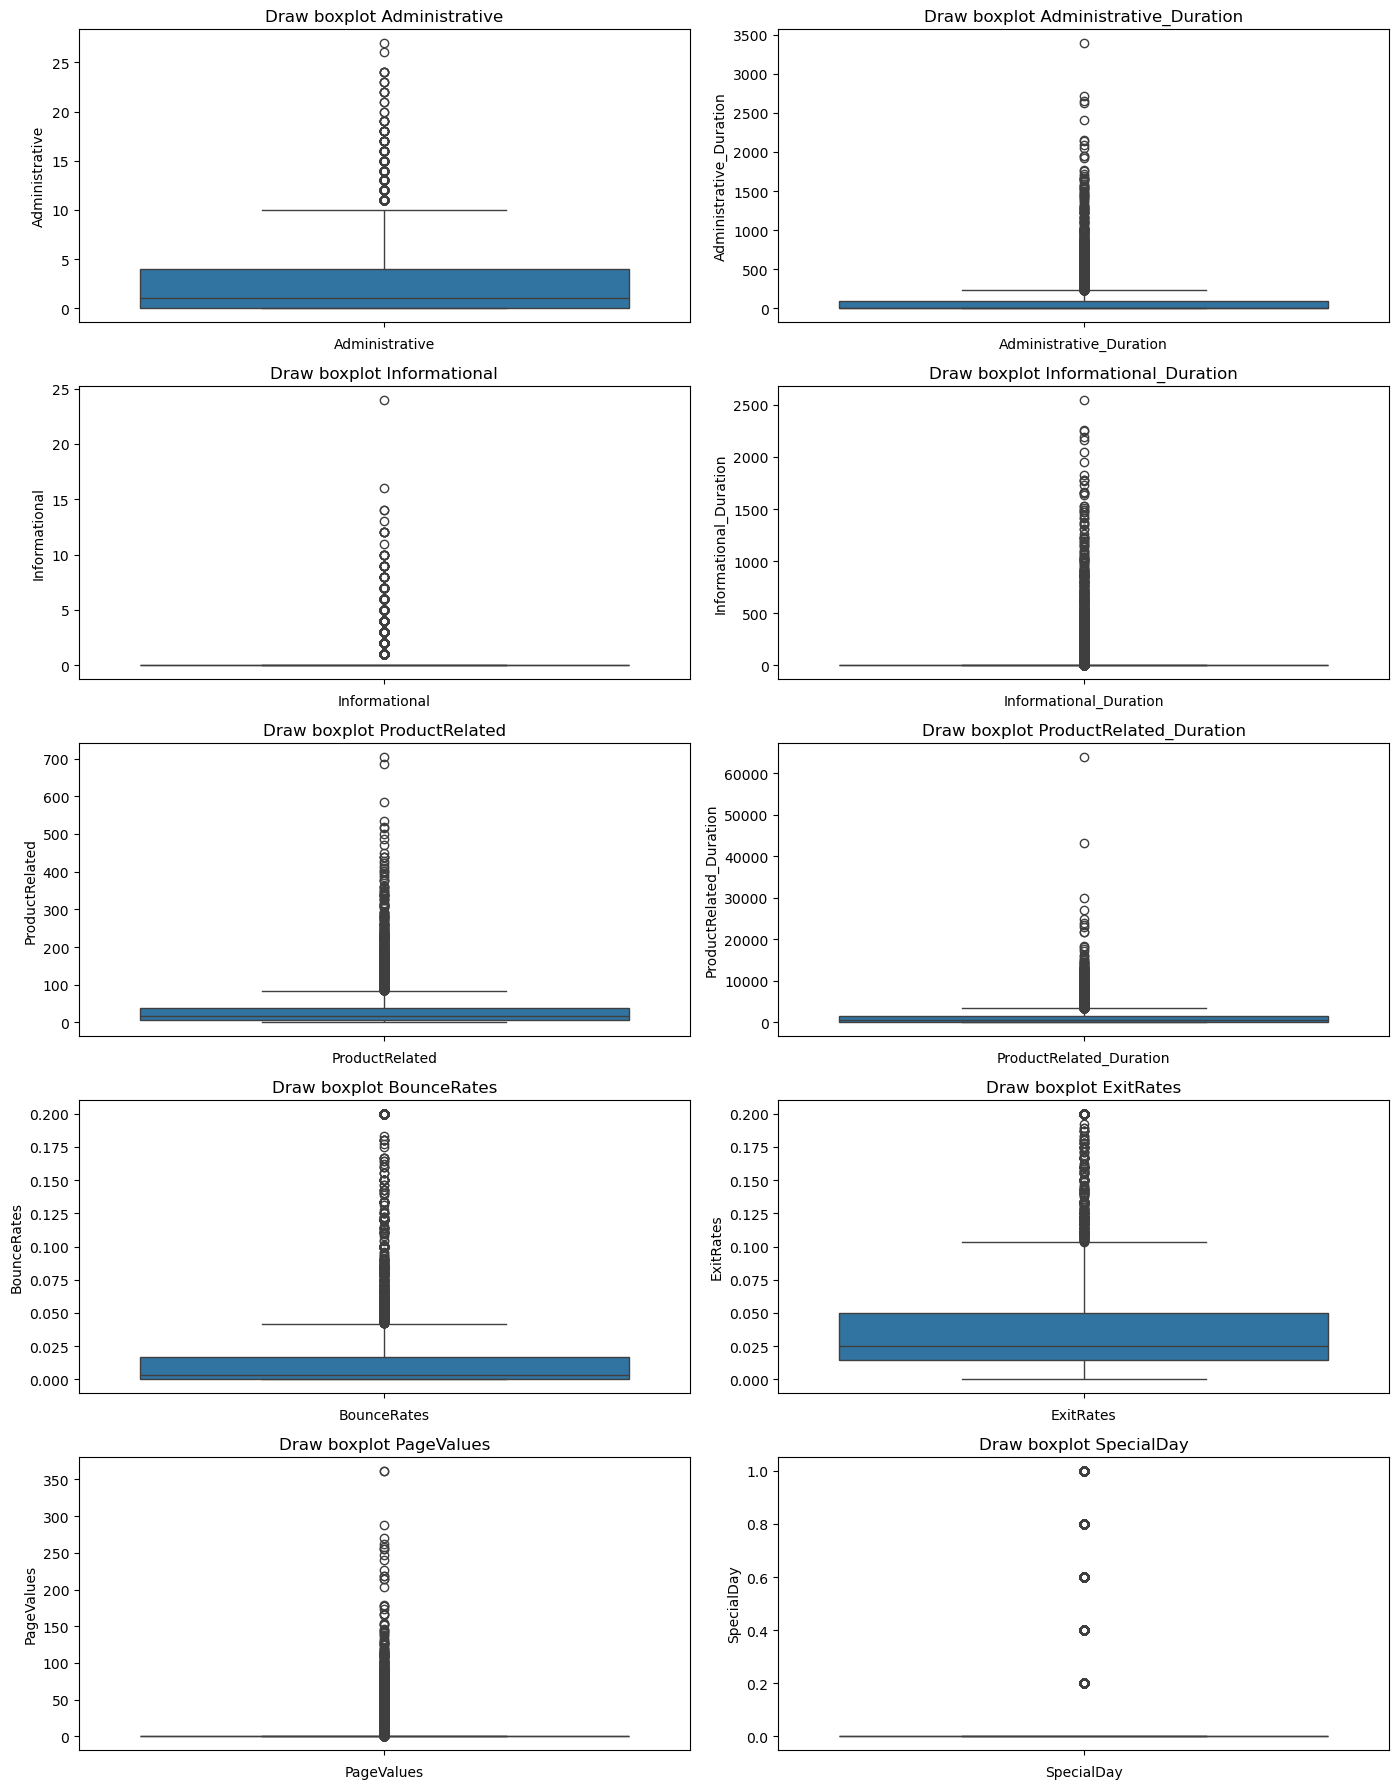

In [30]:
# Draw boxplot the distribution columns
col = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration", "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
fig, axes = plt.subplots(5,2, figsize=(14,18))
axes = axes.flatten()

for index, cols in enumerate (columns_1):
    sns.boxplot(df[cols], ax=axes[index])
    axes[index].set_title(f'Draw boxplot {cols}')
    axes[index].set_xlabel(cols)

plt.tight_layout()
plt.show()

Code Explanation:
- columns_1: are all the numeric columns in the dataset, such as ("Administrative", "Administrative_Duration", "Informational", "Informational_Duration", "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay")
- for index, cols in enumerate (columns_1): first line works as a checker in 2 ways, sns. histplot(df[cols], kde=True, ax=axes[index]) the second line takes the real data of the column, draws the line, and indicates which of the columns need to be drawn in that histogram,  axes[index].set_title(f'Distribution of {cols}') the third line is to give the title,  axes[index].set_xlabel(cols) / axes[index].set_ylabel('Frequency'); the fourth and fifth lines define the X and y.

  
Interpretation (Plot of distribution):
- All the features reveal a positive skewness, especially "Administrative", "Administrative_Duration", "Informational", "Informational_Duration", with the majority of sessions clustered at zero. Meanwhile, "ProductRelated", "ProductRelated_Duration" demonstrate unimodal also right skewness. And "BounceRates" and "ExitRates" represent a more binomial structure, with the first peak near 0.0 and the second one at approx. 0.2.

Interpretation (Draw boxplot):
- All the features confirm a positive skewness; in features such as "Informational", "Informational_Duration", "PageValues", "SpecialDay", the interquartile range almost collapsed at 0.0; that is, it means that approximately 75% of the recorded sessions exhibit 0 values without any positive activity. Meanwhile, "ProductRelated" and "ProductRelated_Duration" demonstrate compact interquartile ranges below 40 pages and 1.500 s. "BounceRates" and "ExitRates" were compared; both features demonstrated high engagement and abandonment on a single page.

### Revenue vs Numerical Features

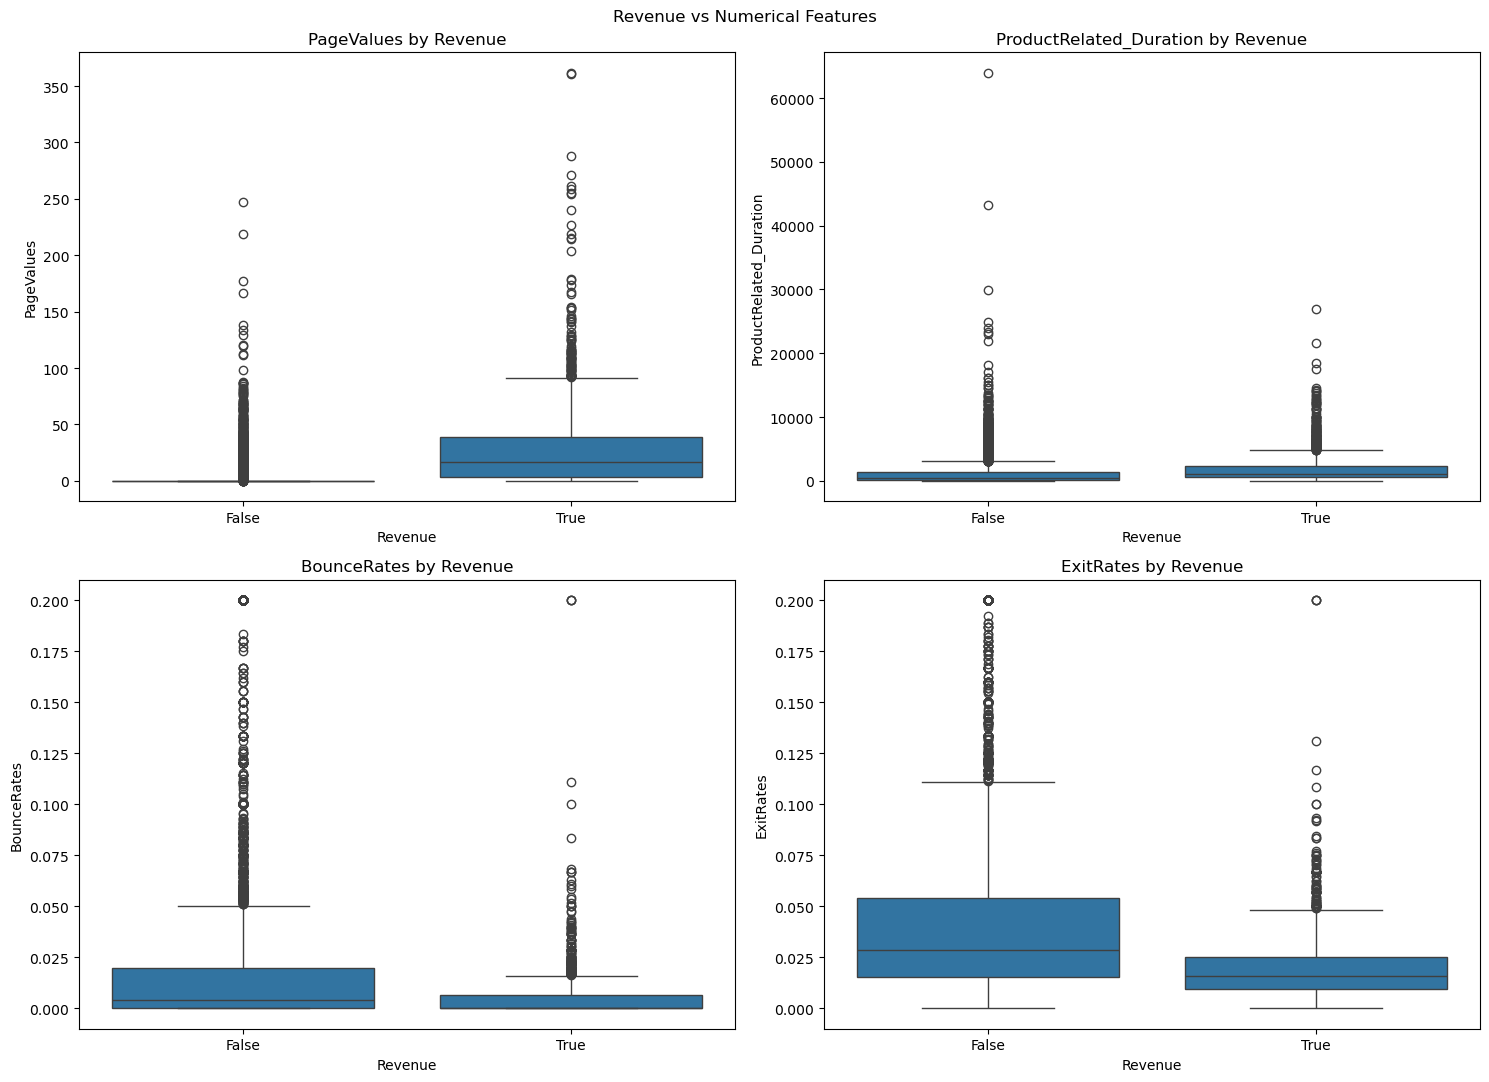

In [33]:
#Bivariate boxplots
fig, axes = plt.subplots(2,2,figsize=(15,11))
fig.suptitle("Revenue vs Numerical Features")

biv_features = ["PageValues", "ProductRelated_Duration", "BounceRates", "ExitRates"]

for index, col in enumerate(biv_features):
    row,col_index = divmod(index,2)
    sns.boxplot(data=df, x="Revenue", y=col, ax=axes[row,col_index])
    axes[row, col_index].set_title(f'{col} by Revenue')
    axes[row, col_index].set_xlabel('Revenue')
    axes[row, col_index].set_ylabel(col)

plt.tight_layout()
plt.show()

Code Explanation:
- bivariate boxplot: illustrates the comparison between PageVales, ProductRelated_Duration, BounceRates, and ExitRates vs Revenue (Target).

Interpretation:
The four features show upper-tail outliers.

### Skewness

In [36]:
# Skewness the distribution 
cols = df.columns.tolist()

for i in cols:
    if df[i].dtype in ['category', 'bool']:
        continue
    else:
        skewness = df[i].skew()
        print(f"Skewness of {i}: {skewness}")

Skewness of Administrative: 1.9603572090790138
Skewness of Administrative_Duration: 5.61571901877419
Skewness of Informational: 4.03646375994314
Skewness of Informational_Duration: 7.579184715734216
Skewness of ProductRelated: 4.341516415550066
Skewness of ProductRelated_Duration: 7.263227682561318
Skewness of BounceRates: 2.947855266695535
Skewness of ExitRates: 2.1487889999009804
Skewness of PageValues: 6.3829642489981335
Skewness of SpecialDay: 3.3026667472572897


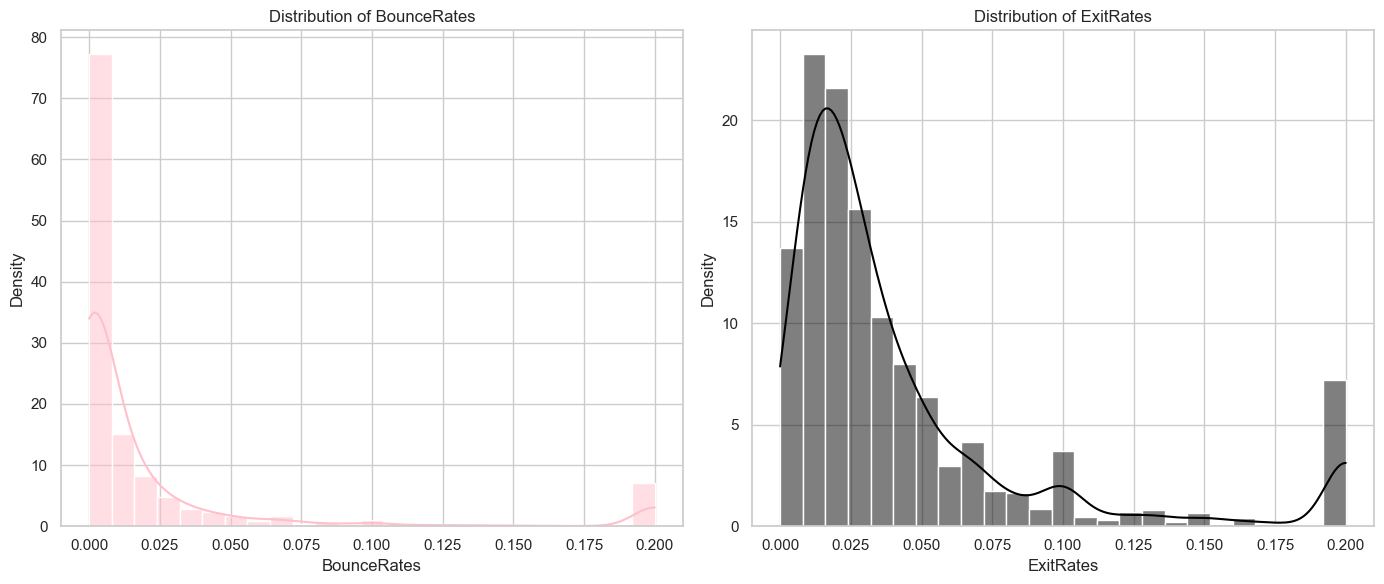

In [37]:
# Set the style of the visualizations
sns.set(style="whitegrid")

# Create a figure with separate plots
plt.figure(figsize=(14, 6))

# Plot for distribution to BounceRates
plt.subplot(1, 2, 1)
sns.histplot(df['BounceRates'].dropna(), bins=25, kde=True, color='pink', stat='density')
plt.title('Distribution of BounceRates')
plt.xlabel('BounceRates')
plt.ylabel('Density')

# Plot for distribution to ExitRates
plt.subplot(1, 2, 2)
sns.histplot(df['ExitRates'].dropna(), bins=25, kde=True, color='black', stat='density')
plt.title('Distribution of ExitRates')
plt.xlabel('ExitRates')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

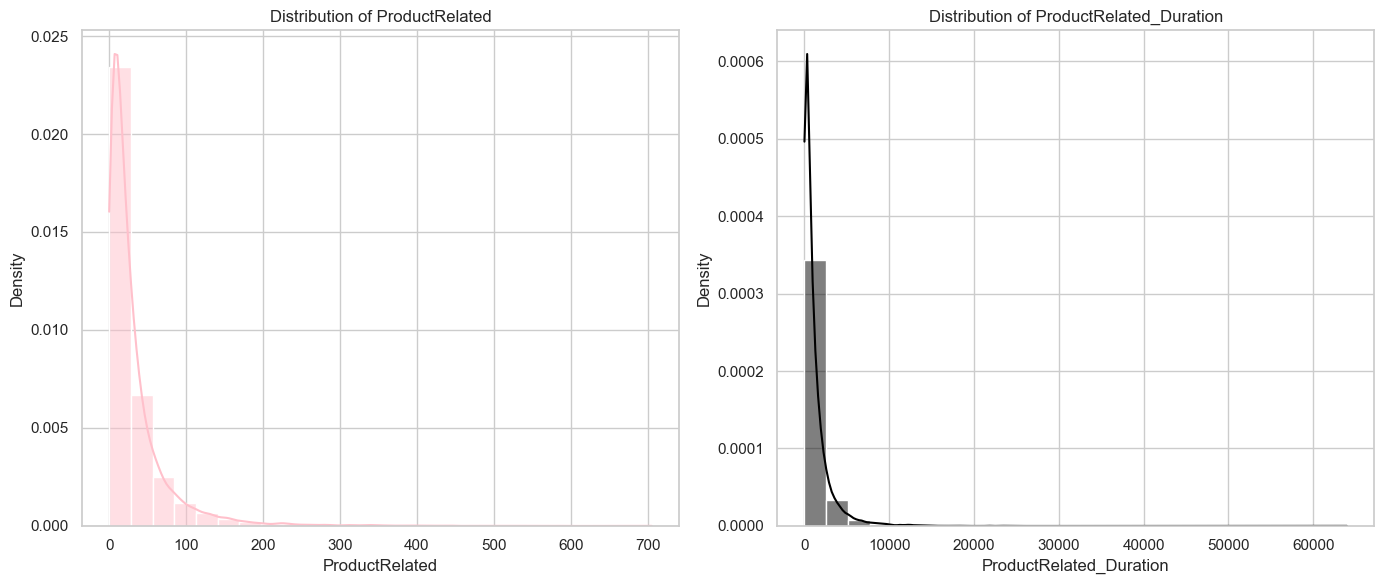

In [38]:
# Set the style of the visualizations
sns.set(style="whitegrid")

# Create a figure with separate plots
plt.figure(figsize=(14, 6))

# Plot for distribution to ProductRelated
plt.subplot(1, 2, 1)
sns.histplot(df['ProductRelated'].dropna(), bins=25, kde=True, color='pink', stat='density')
plt.title('Distribution of ProductRelated')
plt.xlabel('ProductRelated')
plt.ylabel('Density')

# Plot for distribution to ProductRelated_Duration
plt.subplot(1, 2, 2)
sns.histplot(df['ProductRelated_Duration'].dropna(), bins=25, kde=True, color='black', stat='density')
plt.title('Distribution of ProductRelated_Duration')
plt.xlabel('ProductRelated_Duration')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

### Kurtosis

In [40]:
# Kurtosis the distribution 
cols = df.columns.tolist()

for i in cols:
    if df[i].dtype in ['category', 'bool']:
        continue
    else:
        kurtosis = df[i].kurt()
        print(f"Kurtosis of {i}: {kurtosis}")

Kurtosis of Administrative: 4.701146248966736
Kurtosis of Administrative_Duration: 50.556739045990774
Kurtosis of Informational: 26.932266263273007
Kurtosis of Informational_Duration: 76.3168530930904
Kurtosis of ProductRelated: 31.211706654188006
Kurtosis of ProductRelated_Duration: 137.17416374545206
Kurtosis of BounceRates: 7.723159430769027
Kurtosis of ExitRates: 4.017034553345531
Kurtosis of PageValues: 65.63569361316084
Kurtosis of SpecialDay: 9.91365887025184


<>:17: SyntaxWarning: invalid escape sequence '\K'
<>:20: SyntaxWarning: invalid escape sequence '\K'
<>:23: SyntaxWarning: invalid escape sequence '\K'
<>:17: SyntaxWarning: invalid escape sequence '\K'
<>:20: SyntaxWarning: invalid escape sequence '\K'
<>:23: SyntaxWarning: invalid escape sequence '\K'
/var/folders/0q/5jg1_xks2qg49s0snbq77gf40000gp/T/ipykernel_66555/2036084839.py:17: SyntaxWarning: invalid escape sequence '\K'
  axes[0].set_title(f'ProductRelated_Duration\Kurtosis: {kurt_col1:.2f}')
/var/folders/0q/5jg1_xks2qg49s0snbq77gf40000gp/T/ipykernel_66555/2036084839.py:20: SyntaxWarning: invalid escape sequence '\K'
  axes[1].set_title(f'BounceRates\Kurtosis: {kurt_col2:.2f}')
/var/folders/0q/5jg1_xks2qg49s0snbq77gf40000gp/T/ipykernel_66555/2036084839.py:23: SyntaxWarning: invalid escape sequence '\K'
  axes[2].set_title(f'BounceRates\Kurtosis: {kurt_col3:.2f}')


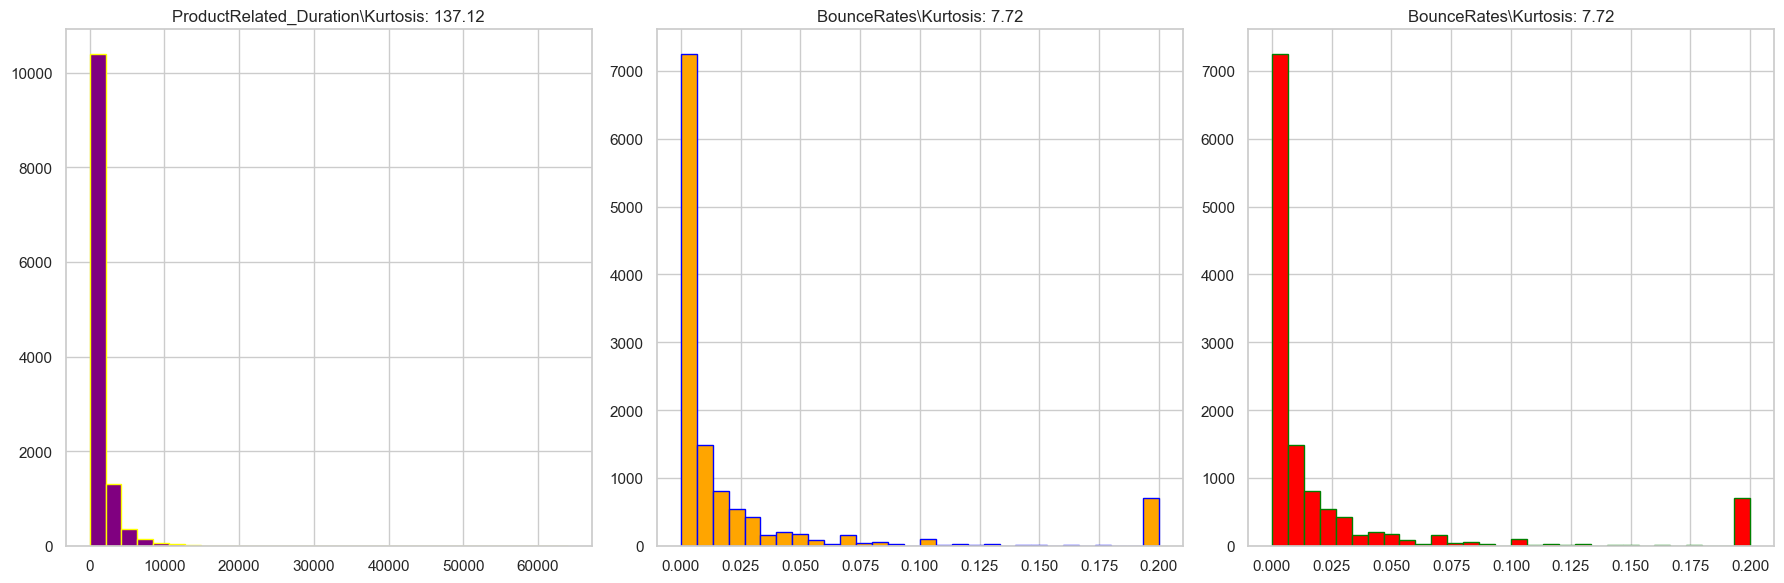

ProductRelated_Duration Kurtosis: 137.12
BounceRates Kurtosis: 7.72
PageValues Kurtosis: 7.72


In [41]:
#Calculate Kurtosis
normal_data = np.random.normal(0, 1, 1000)
leptokurtic_data = np.random.standard_t(2, 1000)
platykurtic_data = np.random.uniform(-2, 2, 1000)

col1 = df["ProductRelated_Duration"]
col2 = df["BounceRates"]
col3 = df["BounceRates"]

kurt_col1 = stats.kurtosis(col1, fisher=True)
kurt_col2 = stats.kurtosis(col2, fisher=True)
kurt_col3 = stats.kurtosis(col3, fisher=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].hist(col1, bins=30, color='purple', edgecolor='yellow')
axes[0].set_title(f'ProductRelated_Duration\Kurtosis: {kurt_col1:.2f}')

axes[1].hist(col2, bins=30, color='orange', edgecolor='blue')
axes[1].set_title(f'BounceRates\Kurtosis: {kurt_col2:.2f}')

axes[2].hist(col3, bins=30, color='red', edgecolor='green')
axes[2].set_title(f'BounceRates\Kurtosis: {kurt_col3:.2f}')

plt.tight_layout()
plt.show()

print(f"ProductRelated_Duration Kurtosis: {kurt_col1:.2f}")
print(f"BounceRates Kurtosis: {kurt_col2:.2f}")
print(f"PageValues Kurtosis: {kurt_col3:.2f}")

Code Explanation:
- Loop: The loop uses in skewness and in kurtosis is the same loop used in the first part to EDA, just change some terminology focus in those two metrics.

Interpretation:
- Positive Skewness: every feature have a high-skewness(>1.0), such as Informational_Duration is 7.58, ProductRelated_Duration is 7.26 until Administrative is 1.96.
- Leptokurtic (Kurtosis): the values are positive across all variables, peaking in ProductRelated_Duration at 137.17, while Administrative is 4.70.
- Both of the metrics confirm extreme zero inflation and heavy-tail.

### Percentage

In [44]:
#Percentage of categorical features
category_columns = ["Revenue", "VisitorType", "Weekend", "Month", "TrafficType", "Region", "Browser", "OperatingSystems"]

for cols in category_columns:
    percentages = df[cols].value_counts(normalize=True)*100
    category = percentages.index[0]
    pct = percentages.iloc[0]
    print(f'Percentages of {cols} ({category}): ; {pct:.2f}%')

Percentages of Revenue (False): ; 84.53%
Percentages of VisitorType (Returning_Visitor): ; 85.57%
Percentages of Weekend (False): ; 76.74%
Percentages of Month (May): ; 27.28%
Percentages of TrafficType (2): ; 31.74%
Percentages of Region (1): ; 38.77%
Percentages of Browser (2): ; 64.57%
Percentages of OperatingSystems (2): ; 53.54%


## Percentile

In [46]:
#Percentile 90th of numerical features
col = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration", "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay"]

for cols in col:
    p90 = df[cols].quantile(0.90)
    print(f'Percentile of {cols}; {p90:.2f}')

Percentile of Administrative; 7.00
Percentile of Administrative_Duration; 224.89
Percentile of Informational; 2.00
Percentile of Informational_Duration; 72.00
Percentile of ProductRelated; 74.00
Percentile of ProductRelated_Duration; 2877.86
Percentile of BounceRates; 0.06
Percentile of ExitRates; 0.10
Percentile of PageValues; 18.86
Percentile of SpecialDay; 0.20


## Z-Score

In [48]:
#Z-score of numerical features
col = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration", "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay"]

for cols in col:
  z_score = stats.zscore(df[cols])
  outliers_zscore = z_score[(z_score > 3) | (z_score < -3)]
  print(f"Z-score of {cols} | Outliers (|Z| > 3): {len(outliers_zscore)} | Max"f" Z: {z_score.max():.2f}")

Z-score of Administrative | Outliers (|Z| > 3): 213 | Max Z: 7.43
Z-score of Administrative_Duration | Outliers (|Z| > 3): 232 | Max Z: 18.77
Z-score of Informational | Outliers (|Z| > 3): 260 | Max Z: 18.50
Z-score of Informational_Duration | Outliers (|Z| > 3): 230 | Max Z: 17.87
Z-score of ProductRelated | Outliers (|Z| > 3): 236 | Max Z: 15.14
Z-score of ProductRelated_Duration | Outliers (|Z| > 3): 219 | Max Z: 32.81
Z-score of BounceRates | Outliers (|Z| > 3): 708 | Max Z: 3.67
Z-score of ExitRates | Outliers (|Z| > 3): 713 | Max Z: 3.23
Z-score of PageValues | Outliers (|Z| > 3): 259 | Max Z: 19.17
Z-score of SpecialDay | Outliers (|Z| > 3): 479 | Max Z: 4.72


Code Explanation:
- Loop: The loop uses is the same loop used in the first and second part to EDA, just change some terminology focus in those three metrics. Considering that Percentage is used only for categorical features.

Interpretation (Percentage):
- Revenue has 84.53% (false), which indicates that the customer does not finish the process. More than 85.57% of the visitors are regular clients; this means that the website has a large percentage that depends only on regular clients, besides demonstrating that the majority of the navigation is made during the weekdays, and May is the month with the most concentrated seasonality.

Interpretation (90th percentile):
- While the majority of the median is 0.0, the 90th percentile demonstrates that 7 features have some activities. For instance: ProductRelated with 74.00 means that the user visits around 74 websites and spends around 2877.86s (ProductRelated_Duration). However, a BounceRate of 0.06 and ExitRates of 0.10 indicate that the user has more interaction on the website before leaving.

Interpretation (z-score):
- All the variables have observations>3, such as ExitRates of 713 and BounceRates of 708, with Max Z values such as ProductRelated_Duration of 32.81 or PageValues of 19.17. Demostrating a possibility of those kind of user that spend too much time on the web or who buy plenty of things.

## Coefficient of correlation

In [51]:
# Calculate the coefficient of correlation of numerical features
correlation = df['Administrative'].corr(df['Administrative_Duration'])
print(f"Coefficient of Correlation between Administrative and Administrative_Duration: {correlation}")

correlation = df['Informational'].corr(df['Informational_Duration'])
print(f"Coefficient of Correlation between Informational and Informational_Duration: {correlation}")

correlation = df['ProductRelated'].corr(df['ProductRelated_Duration'])
print(f"Coefficient of Correlation between ProductRelated and ProductRelated_Duration: {correlation}")

correlation = df['BounceRates'].corr(df['ExitRates'])
print(f"Coefficient of Correlation between BounceRates and ExitRates: {correlation}")

correlation = df['PageValues'].corr(df['SpecialDay'])
print(f"Coefficient of Correlation between PageValues and SpecialDay: {correlation}")

Coefficient of Correlation between Administrative and Administrative_Duration: 0.6015833421250225
Coefficient of Correlation between Informational and Informational_Duration: 0.6189548617814581
Coefficient of Correlation between ProductRelated and ProductRelated_Duration: 0.8609268361763696
Coefficient of Correlation between BounceRates and ExitRates: 0.9130043961815208
Coefficient of Correlation between PageValues and SpecialDay: -0.06354127178535042


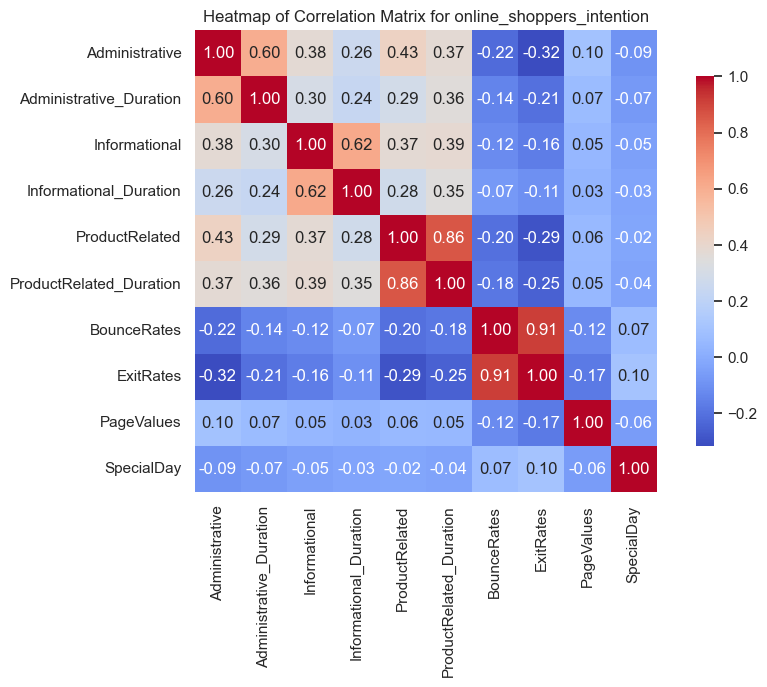

In [52]:
# Select only numeric columns for correlation calculation
numeric_df = df.select_dtypes(include=['float64', 'int64'])

# Calculate the correlation matrix
correlation_matrix = numeric_df.corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 6))

# Create a heatmap with the correlation matrix
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, cbar_kws={"shrink": .8})
# Set the title
plt.title('Heatmap of Correlation Matrix for online_shoppers_intention')

# Show the plot
plt.show()

Code Explanation:
- Comparison between each numerical feature to see the correlation between them.

Interpretation:
- ExitRates vs BounceRate of 0.91 could mean that when the website is ot working properly, the user does not come back and leaves the website.
- ProductRelated vs ProductRelated_Duration of 0.86: when the user wants to buy something or is looking for something, they spend more time on the website.
- SpecialDay vs PageValues of -0.06 means that does not exist any relation between the SpecialDay and have more sales for those celebration days.

## Q-Q Plot

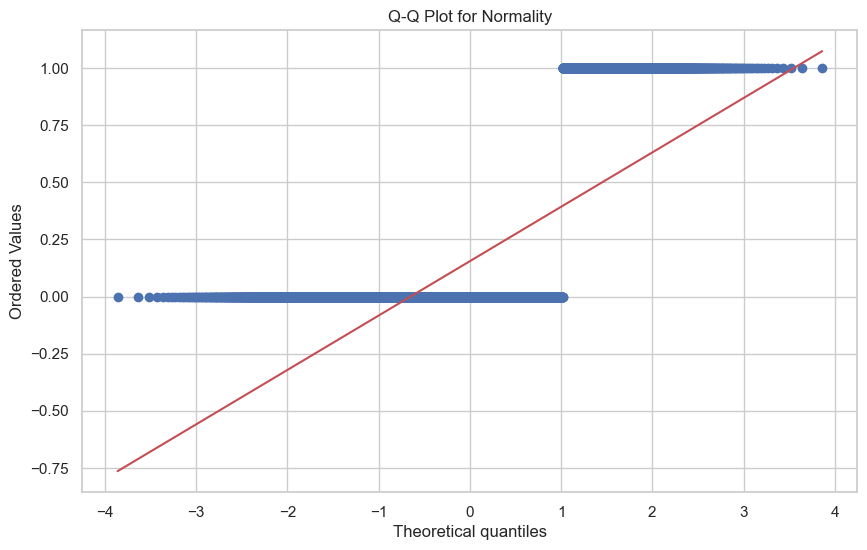

In [55]:
# Q-Q Plot to check normality visually
y = df["Revenue"] # Target variable 
X = df[["PageValues", "ProductRelated_Duration", "ProductRelated", "BounceRates", "ExitRates", "Administrative_Duration"]]
           
plt.figure(figsize=(10, 6))
stats.probplot(y, dist="norm", plot=plt)
plt.title('Q-Q Plot for Normality')
plt.show()

Code Explanation:
- y: defined as "Revenue".
- X: are 6 features "PageValues", "ProductRelated_Duration", "ProductRelated", "BounceRates", "ExitRates", "Administrative_Duration".


Interpretation:
- Revenue as binary features is isolating, and the X contains the primary numerical predictors. The plot helps to see the bivariate comparison testing across user engagement metrics

## Inferential Statistics

### Population mean

In [59]:
# Population mean with ProductRelated_Duration
duration_data = df["ProductRelated_Duration"]
n_duration = len(duration_data)
mean_duration = np.mean(duration_data)
std_duration = np.std(duration_data, ddof=1)
stderror_duration = stats.sem(duration_data)

print(f"Sample (n):{n_duration}")
print(f"Sample mean:{mean_duration:.2f}s")
print(f"Sample std:{std_duration:.2f}s")
print(f"Sample stderror:{stderror_duration:.2f}s")

Sample (n):12330
Sample mean:1194.75s
Sample std:1913.67s
Sample stderror:17.23s


### Population Proportion

In [61]:
#Revenue - Population proportion
n_total = len(df)
purchases = df["Revenue"].sum()
purch_hat = purchases / n_total
se_proportion = np.sqrt((purch_hat *(1-purch_hat))/ n_total)

print(f"Total Sessions (n): {n_total}")
print(f"Completed Purchases: {purchases}")
print(f"Sample Proportion (purch_hat): {purch_hat:.4f} ({purch_hat*100:.2f}%)")
print(f"Standard Error of Proportion (SE): {se_proportion:.4f}")

Total Sessions (n): 12330
Completed Purchases: 1908
Sample Proportion (purch_hat): 0.1547 (15.47%)
Standard Error of Proportion (SE): 0.0033


### Confidence levels

In [63]:
confidential_levels = [0.90,0.95,0.99]
print("Confidence of intervals of ProductRelated_Duration")

for conf_level in confidential_levels:
    lower,upper = stats.t.interval(conf_level, df=n_duration -1, loc=mean_duration, scale=stderror_duration)
    width = upper - lower
    print(f"{int(conf_level*100)}% CI:[{lower:.2f}s, {upper:.2f}s] | Width: {width: .2f}s")

# Confidential levels of population proportion
print("Confidence Intervals with Revenue")
for conf_level in confidential_levels:
    z_crit = stats.norm.ppf(1 - (1 - conf_level) / 2)
    margin_error = z_crit * se_proportion
    lower = purch_hat - margin_error
    upper = purch_hat + margin_error
    width = upper - lower
    print(f"{int(conf_level*100)}% CI: [{lower*100:.2f}%, {upper*100:.2f}%] | Width: {width*100:.2f}%")

Confidence of intervals of ProductRelated_Duration
90% CI:[1166.40s, 1223.10s] | Width:  56.70s
95% CI:[1160.96s, 1228.53s] | Width:  67.56s
99% CI:[1150.35s, 1239.14s] | Width:  88.80s
Confidence Intervals with Revenue
90% CI: [14.94%, 16.01%] | Width: 1.07%
95% CI: [14.84%, 16.11%] | Width: 1.28%
99% CI: [14.64%, 16.31%] | Width: 1.68%


Code Explanation:
- To estimate the population parameter from n, the confidence intervals were set at 3 levels (90%,95% and 99%) using a loop.
- Population mean: the feature chosen was ProductRelated_Duration, using a sample mean standard error.
- Population proportion: the feature chosen was the target Revenue, calculated std * stderror to validate both hat and 1-hat.

Interpretation
N is 12.330 sessions, and the average time on the website is around 1.194,75s; meanwhile, the std is 1.913,67, which means that there is a big gap between the user with a few navigations and the user that spends hours on the page, but the stderror is low at 17.23s, so the mean population has more precision.

Of the total of n, only 1.908 users finish the process, and p is 15.47% with a standard error of 0.33%. However, if the confidence level goes up from 90% to 99%, the width grows as well; for instance, ProductRelated_Duration passes from 56.70s at 90% to 67.60s at 95% and finishes with 88.80s at 99%, and Revenue passes from 1.07% at 90% to 1.28% at 95% and finishes with 1.68% at 99%.

## Non-Parametric and Parametric inferential 

### Non-Parametric

#### Mann-Whitney U Test

##### 1.1 PageValues vs Revenue

B-Question: Do users who complete a purchase, Revenue = True, visit higher-value pages, PageValues, during the session compared to users who leave without purchasing, Revenue = False?

H0: There is no difference in the distribution of "PageValues" between sessions with Revenue = True and those with Revenue = False.

H1: There is a difference in the distribution of "PageValues" between sessions with Revenue = True and those with Revenue = False.

In [199]:
#Mann-Whitney U Test (PageValues vs Revenue)
pageval_realusers = df[df['Revenue'] == True]['PageValues']
pageval_NONrealusers = df[df['Revenue'] == False]['PageValues']

u_stat1, u_p1 = mannwhitneyu(pageval_realusers, pageval_NONrealusers, alternative='two-sided')
print("Mann-Whitney U Test (PageValues vs Revenue)")
print(f"U-statistic = {u_stat1:.4f}, p-value = {u_p1:.4e}")
if u_p1 < 0.05:
    print("→ Reject H₀: Distributions differ between users\n")
else:
    print("→ Fail to reject H₀: No significant difference\n")

Mann-Whitney U Test (PageValues vs Revenue)
U-statistic = 17166757.0000, p-value = 0.0000e+00
→ Reject H₀: Distributions differ between users



Non-Parametric Explanation:
Mann-Whitney U test: is selected because "PageValues" has extreme positive skewness and the majority of the concentration is 0; that means it is a standard independent test that is needed.

Interpretation:
Using Mann-Whitney U-statistic = 17166757.0000 and p-value = 0.0000e+00, the H0 is rejected due to the evidence demonstrating that PageValues are completely different between purchasing and non-purchasing sessions.

##### 1.2 ProductRelated_Duration vs Revenue

B-Question: Do users who finish buying something spend more time on the website than users who do not finish the process?

H0: The distribution of ProductRelated_Duration is identical for purchasing sessions Revenue = True, and non-purchasing sessions Revenue = False.

H1: The distribution of ProductRelated_Duration is different for purchasing sessions Revenue = True, and non-purchasing sessions Revenue = False.

In [194]:
#Mann-Whitney U Test (ProductRelated_Duration vs Revenue)
product_relat_durat_buyers = df[df['Revenue'] == True]['ProductRelated_Duration']
product_relat_durat_NONbuyers= df[df['Revenue'] == False]['ProductRelated_Duration']

u_stat2, u_p2 = mannwhitneyu(product_relat_durat_buyers, product_relat_durat_NONbuyers, alternative='two-sided')
print("Mann-Whitney U Test (ProductRelated_Duration vs Revenue)")
print(f"U-statistic = {u_stat2:.4f}, p-value = {u_p2:.4e}")
if u_p2 < 0.05:
    print("→ Reject H₀: ProductRelated_Duration distributions differ between buyers and non-buyers\n")
else:
    print("→ Fail to reject H₀: No significant difference\n")

Mann-Whitney U Test (ProductRelated_Duration vs Revenue)
U-statistic = 13382713.0000, p-value = 5.3323e-128
→ Reject H₀: ProductRelated_Duration distributions differ between buyers and non-buyers



Non-Parametric Explanation:
Mann-Whitney U test: is selected because "ProductRelated_Duration" has extreme positive skewness and the majority of the concentration is 0; that means it is a standard independent test that is needed.

Interpretation:
Using Mann-Whitney U-statistic = 13382713.0000 and p-value = 5.3323e-128, the H0 is rejected due to the evidence demonstrating that ProductRelated_Duration are significantly different between purchasing and non-purchasing sessions.

##### 1.3 ExitRates vs Revenue

B-Question: Do purchasing sessions exhibit significantly lower page exit rates, ExitRates, than non-purchasing sessions?

H0: The distribution of ExitRates is identical for purchasing sessions Revenue = True, and non-purchasing sessions Revenue = False.

H1: The distribution of ExitRates differs significantly between purchasing sessions, Revenue = True, and non-purchasing sessions, Revenue = False.

In [197]:
#Mann-Whitney U Test (ExitRates vs Revenue)
exit_rates_buyer = df[df['Revenue'] == True]['ExitRates']
exit_rates_NONbuyer = df[df['Revenue'] == False]['ExitRates']

u_stat3, u_p3 = mannwhitneyu(exit_rates_buyer, exit_rates_NONbuyer, alternative='two-sided')
print("Mann-Whitney U Test (ExitRates vs Revenue)")
print(f"U-statistic = {u_stat3:.4f}, p-value = {u_p3:.4e}")
if u_p3 < 0.05:
    print("→ Reject H₀: ExitRates distributions differ between buyers and non-buyers\n")
else:
    print("→ Fail to reject H₀: No significant difference\n")

Mann-Whitney U Test (ExitRates vs Revenue)
U-statistic = 5903869.0000, p-value = 1.1568e-175
→ Reject H₀: ExitRates distributions differ between buyers and non-buyers



Non-Parametric Explanation:
Mann-Whitney U test: is selected because "ExitRates" is bounded between 0 and 1 with strong right-skewness; that means it is not normally distributed and requires a non-parametric independent 2 sample test

Interpretation:
Using Mann-Whitney U-statistic = 5903869.0000 and p-value = 1.1568e-175, the H0 is rejected due to the evidence demonstrating that ExitRates are significantly different between purchasing and non-purchasing sessions.

##### Interpretation across the 3-test Mann-Whitney U Test

H0 is consistently rejected, confirming that purchasing, Revenue = True, and non-purchasing, Revenue = False, even though the sessions demonstrated distinct behavioural distributions. Users show stronger transaction intent, PageValues,  and higher product exploration, ProductRaleted_Duration, in comparison to less interaction friction and premature abandonment, ExitRates.

#### Kruskal-Wallis H Test

##### 1.1 ProductRelated+_Duration vs VisitorType

B-Question: Does the time that a user spends (ProductRelated_Duration) on the website fluctuate by the type of user (VisitorType)?

H0: The distribution of "ProductRelated_Duration" is the same across "Returning_Visitor", "New_Visitor" or "other".

H1: At least one VisitorType make a difference in the distributions of "ProductRelated_Duration".

In [201]:
#Kruskal-Wllis H Test (ProductRelated_Duration vs VisitorType)
prduration_returning = df[df['VisitorType'] == "Returning_Visitor"]["ProductRelated_Duration"]
prduration_new = df[df['VisitorType'] == "New_Visitor"]["ProductRelated_Duration"]
prduration_other = df[df['VisitorType'] == "Other"]["ProductRelated_Duration"]

h_stat1, h_p1 = stats.kruskal(prduration_returning, prduration_new, prduration_other)
print(f"H-statistic = {h_stat1:.4f}, p-value = {h_p1:.4e}")
if h_p1 < 0.05:
    print("→ Reject H₀: Distributions differ across visitor types\n")
else:
    print("→ Fail to reject H₀: No significant difference\n")

H-statistic = 184.5161, p-value = 8.5672e-41
→ Reject H₀: Distributions differ across visitor types



Non-Parametric Explanation: Kruskal-Wallis H Tests is selected to compare 3 independent groups on ProductRelated_Duration, which violates normality assumptions.

Interpretation: Using Kruskal-Wallis H Test = 184.5161 and p-value = 8.5672e-41, the H0 is rejected due to the evidence that the time users spend browsing product_related pages differs significantly across visitors ("Returning_Visitor", "New_Visitor", and "Other").

##### 1.2 PageValues vs VisitorType

B-Question: Does the average monetary value of pages visited, PageValues, differ across user categories, VisitorType (Returning_Visitor, New_Visitor and Other)?

H0: The distribution of "PageValues" is the same across "Returning_Visitor", "New_Visitor" or "other".

H1: At least one VisitorType has a significantly different "PageValues" distribution.

In [226]:
#Kruskal-Wllis H Test (PageValues vs VisitorType)
pagevalue_returning = df[df['VisitorType'] == "Returning_Visitor"]["PageValues"]
pagevalue_new = df[df['VisitorType'] == "New_Visitor"]["PageValues"]
pagevalue_other = df[df['VisitorType'] == "Other"]["PageValues"]

h_stat2, h_p2 = stats.kruskal(pagevalue_returning, pagevalue_new, pagevalue_other)
print(f"H-statistic = {h_stat2:.4f}, p-value = {h_p2:.4e}")
if h_p2 < 0.05:
    print("→ Reject H₀: PageValues distributions differ across visitor types\n")
else:
    print("→ Fail to reject H₀: No significant difference\n")

H-statistic = 7.2517, p-value = 2.6626e-02
→ Reject H₀: PageValues distributions differ across visitor types



Non-Parametric Explanation: Kruskal-Wallis H Tests is selected to compare 3 independent groups on PageValues, which has extreme positive skewness and a high quantity of 0.

Interpretation: Using Kruskal-Wallis H Test = 7.2517, p-value = 7.2517, the H0 is rejected due to evidence that "PageValues" differs significantly across at least one of the visitors ("Returning_Visitor", "New_Visitor", and "Other").

##### 1.3 ProductRelated_Duration vs Month

B-Question: Does the user spend browsing product-related pages, PoductRelated_Duration, fluctuate across different months, Month?

H0: The distribution of "ProductRelated_Duration" is the same across  all the year, "Month".

H1: At least one Month has a significantly different "ProductRelated_Duration" distribution.

In [231]:
#Kruskal-Wllis H Test (ProductRelated_Duration vs Month)
month = [group["ProductRelated_Duration"].values for _, group in df.groupby("Month")]

h_stat3, h_p3 = stats.kruskal(*month)
print("ProductRelated_Duration vs Month")
print(f"H-statistic = {h_stat3:.4f}, p-value = {h_p3:.4e}")
if h_p3 < 0.05:
    print("→ Reject H₀: ProductRelated_Duration distributions differ across months\n")
else:
    print("→ Fail to reject H₀: No significant difference\n")

ProductRelated_Duration vs Month
H-statistic = 427.6290, p-value = 1.7305e-86
→ Reject H₀: ProductRelated_Duration distributions differ across months



Non-Parametric Explanation: Kruskal-Wallis H Test is selected to compare 10 independent groups, Month,  on ProductRelated_Duration, which has extreme positive skewness and violates normality.

Interpretation: Using Kruskal-Wallis H Test = 427.6290, p-value = 1.7305e-86, the H0 is rejected due to evidence demonstrated, ProductRelated_Visito, varies across different months.

##### Interpretation across the 3-test Kruskal-Wallis H Test

H0 is consistently rejected, confirming that user browsing and transaction intent are non-uniform across customer segments and seasons. Then, both time/product, ProductRelated_Duration, and monetisation value, PageValues, differ by VisitorType, meanwhile, Month need a segment-specific and seasonal strategy

### Chi Square (X2)

##### 1.1 VisitorType vs Revenue

B-Question: Is there a statistical relationship between "VisitorType" and whether a session finishes with Revenue?

H0: "VisitorType" and "Revenue" are independent.

H1: "VisitorType" and "Revenue" are associated.

In [268]:
observed_df = pd.crosstab(df["VisitorType"], df["Revenue"])
observed_df

Revenue,False,True
VisitorType,,
New_Visitor,1272,422
Other,69,16
Returning_Visitor,9081,1470


In [270]:
# Calculate row totals, column totals, and grand total
row_totals = observed_df.sum(axis=1)  # Total for each row (New_visitor, Other, Returning_visitor)
column_totals = observed_df.sum(axis=0)  # Total for each column (False, True)
grand_total = observed_df.sum().sum()  # Sum of all values in the table

# Display totals
row_totals, column_totals, grand_total

(VisitorType
 New_Visitor           1694
 Other                   85
 Returning_Visitor    10551
 dtype: int64,
 Revenue
 False    10422
 True      1908
 dtype: int64,
 np.int64(12330))

In [272]:
# Calculate the expected frequencies using the formula (Row Total * Column Total) / Grand Total
expected = np.outer(row_totals, column_totals) / grand_total
expected_df = pd.DataFrame(expected, columns=['False', 'True'], index=['New_visitor', 'Other', 'Returning_visitor'])
expected_df

,False,True
New_visitor,1431.862774,262.137226
Other,71.846715,13.153285
Returning_visitor,8918.290511,1632.709489


In [80]:
# Calculate the Chi-Square statistic manually
chi2_stat_manual = np.sum((observed_df.values - expected_df.values) ** 2 / expected_df.values)

# Display the Chi-Square statistic
chi2_stat_manual

np.float64(135.2519228192047)

In [131]:
# Degrees of freedom (df) for a 3x2 table
deg_of_free = (3 - 1) * (2 - 1) # (rows - 1) * (columns - 1)

# Display degrees of freedom
deg_of_free

2

In [133]:
# Significance level (alpha)
alpha = 0.05

# Calculate the critical value from the Chi-Square distribution (inverse CDF)
critical_value = chi2.ppf(1 - alpha, deg_of_free)

# Display the critical value
critical_value

np.float64(5.991464547107979)

In [135]:
# Output the results
if chi2_stat_manual > critical_value:
    result = f"Chi-Square Statistic: {chi2_stat_manual}\nCritical Value: {critical_value}\nReject the null hypothesis: There is a significant relationship between VisitorType and Revenue."
else:
    result = f"Chi-Square Statistic: {chi2_stat_manual}\nCritical Value: {critical_value}\nFail to reject the null hypothesis: There is no significant relationship between VisitorType and Revenue."

result

'Chi-Square Statistic: 135.2519228192047\nCritical Value: 5.991464547107979\nReject the null hypothesis: There is a significant relationship between VisitorType and Revenue.'

In [137]:
# Compute the Chi-Square statistic, p-value, degrees of freedom, and expected frequencies using scipy's chi2_contingency
chi2_stat, p_value, df_scipy, expected_scipy = chi2_contingency(observed_df)

# Display p-value and other results
chi2_stat, p_value, df_scipy, expected_scipy

(np.float64(135.2519228192047),
 np.float64(4.269904152293867e-30),
 2,
 array([[1431.86277372,  262.13722628],
        [  71.84671533,   13.15328467],
        [8918.29051095, 1632.70948905]]))

In [246]:
# Output the results using p-value
if p_value < alpha:
    result = f"Chi-Square Statistic: {chi2_stat}\nCritical Value: {critical_value}\np-value: {p_value}\nReject the H0: There is a significant relationship between VisitorType and Revenue."
else:
    result = f"Chi-Square Statistic: {chi2_stat}\nCritical Value: {critical_value}\np-value: {p_value}\nFail to reject the H0:  There is no significant relationship between VisitorType and Revenue."

result

'Chi-Square Statistic: 135.2519228192047\nCritical Value: 5.991464547107979\np-value: 4.269904152293867e-30\nReject the H0: There is a significant relationship between VisitorType and Revenue.'

Non-Parametric Explanation: Chi-Square is selected because both features "VisitorType and Revenue" are categorical, besides both accepted the frequencies exceed the minimum threshold of 13.15.

Interpretation: Using Chi-Square statistic = 135.2519228192047, p-value = 4.269904152293867e-30, deg_of_free = 2 ans the critical value = 5.991464547107979 the H0 is rejected due to evidence demonstrated that, VisitorType, and, Revenue, are associated.

##### 1.2 Weekend vs Revenue

B-Question: Is there a statistical relationship between browsing on "Weekend" and whether a session finishes with Revenue?

H0: "Weekend" and "Revenue" are independent.

H1: "Weekend" and "Revenue" are associated.

In [258]:
observed_df2 = pd.crosstab(df["Weekend"], df["Revenue"])
observed_df2

Revenue,False,True
Weekend,,
False,8053,1409
True,2369,499


In [301]:
# Calculate row totals, column totals, and grand total
row_totals2 = observed_df2.sum(axis=1)  # Total for each row (False, True)
column_totals2 = observed_df2.sum(axis=0)  # Total for each column (False, True)
grand_total2 = observed_df2.sum().sum()  # Sum of all values in the table

# Display totals
row_totals2, column_totals2, grand_total2

(Weekend
 False    9462
 True     2868
 dtype: int64,
 Revenue
 False    10422
 True      1908
 dtype: int64,
 np.int64(12330))

In [262]:
# Calculate the expected frequencies using the formula (Row Total * Column Total) / Grand Total
expected2 = np.outer(row_totals2, column_totals2) / grand_total2
expected_df2 = pd.DataFrame(expected2, columns=observed_df2.columns, index=observed_df2.index)
expected_df2

Revenue,False,True
Weekend,,
False,7997.807299,1464.192701
True,2424.192701,443.807299


In [264]:
# Calculate the Chi-Square statistic manually
chi2_stat_manual2 = np.sum((observed_df2.values - expected_df2.values) ** 2 / expected_df2.values)

# Display the Chi-Square statistic
chi2_stat_manual2

np.float64(10.58183514829754)

In [266]:
# Degrees of freedom (df) for a 3x2 table
deg_of_free2 = (2 - 1) * (2 - 1) # (rows - 1) * (columns - 1)

# Display degrees of freedom
deg_of_free2

1

In [274]:
# Significance level (alpha)
alpha2 = 0.05

# Calculate the critical value from the Chi-Square distribution (inverse CDF)
critical_value2 = chi2.ppf(1 - alpha2, deg_of_free2)

# Display the critical value
critical_value2

np.float64(3.841458820694124)

In [282]:
# Output the results
if chi2_stat_manual2 > critical_value2:
    result2 = f"Chi-Square Statistic: {chi2_stat_manual2}\nCritical Value: {critical_value2}\nReject the null hypothesis: 'Weekend' and 'Revenue' are associated."
else:
    result2 = f"Chi-Square Statistic: {chi2_stat_manual2}\nCritical Value: {critical_value2}\nFail to reject the null hypothesis: 'Weekend' and 'Revenue' are independent."

result2

"Chi-Square Statistic: 10.58183514829754\nCritical Value: 3.841458820694124\nReject the null hypothesis: 'Weekend' and 'Revenue' are associated."

In [288]:
# Compute the Chi-Square statistic, p-value, degrees of freedom, and expected frequencies using scipy's chi2_contingency
chi2_stat2, p_value2, df_scipy, expected_scipy2 = chi2_contingency(observed_df2)

# Display p-value and other results
chi2_stat2, p_value2, df_scipy, expected_scipy2

(np.float64(10.390978319534856),
 np.float64(0.0012663251061221968),
 1,
 array([[7997.80729927, 1464.19270073],
        [2424.19270073,  443.80729927]]))

In [290]:
# Output the results using p-value
if p_value2 < alpha:
    result2 = f"Chi-Square Statistic: {chi2_stat2}\nCritical Value: {critical_value2}\np-value: {p_value2}\nReject the H0: There is a significant relationship between Weekend and Revenue."
else:
    result2 = f"Chi-Square Statistic: {chi2_stat2}\nCritical Value: {critical_value2}\np-value: {p_value2}\nFail to reject the H0:  There is no significant relationship between Weekend and Revenue."

result2

'Chi-Square Statistic: 10.390978319534856\nCritical Value: 3.841458820694124\np-value: 0.0012663251061221968\nReject the H0: There is a significant relationship between Weekend and Revenue.'

Non-Parametric Explanation: Chi-Square is selected because both features "Weekend and Revenue" are categorical, and all expected cell  frequencies exceed the minimum threshold of 5.

Interpretation: Using Chi-Square statistic = 10.390978319534856, p-value = 0.00126632510612219, deg_of_free = 1, and the critical value = 3.841458820694124, the H0 is rejected due to evidence demonstrated that, Weekend, and, Revenue, are associated.

##### 1.3 Month vs Revenue

B-Question: Is there a statistical relationship between the "Month" of the visit and whether a session finishes with "Revenue"?

H0: "Weekend" and "Revenue" are independent.

H1: "Weekend" and "Revenue" are associated.

In [299]:
observed_df3 = pd.crosstab(df["Month"], df["Revenue"])
observed_df3

Revenue,False,True
Month,,
Aug,357,76
Dec,1511,216
Feb,181,3
Jul,366,66
June,259,29
Mar,1715,192
May,2999,365
Nov,2238,760
Oct,434,115


In [303]:
# Calculate row totals, column totals, and grand total
row_totals3 = observed_df3.sum(axis=1)  # Total for each row (Agu, Dec, Feb, Jul, June, Mar, May, Nov, Oct, Sep)
column_totals3 = observed_df3.sum(axis=0)  # Total for each column (False, True)
grand_total3 = observed_df3.sum().sum()  # Sum of all values in the table

# Display totals
row_totals3, column_totals3, grand_total3

(Month
 Aug      433
 Dec     1727
 Feb      184
 Jul      432
 June     288
 Mar     1907
 May     3364
 Nov     2998
 Oct      549
 Sep      448
 dtype: int64,
 Revenue
 False    10422
 True      1908
 dtype: int64,
 np.int64(12330))

In [305]:
# Calculate the expected frequencies using the formula (Row Total * Column Total) / Grand Total
expected3 = np.outer(row_totals3, column_totals3) / grand_total3
expected_df3 = pd.DataFrame(expected3, columns=observed_df3.columns, index=observed_df3.index)
expected_df3

Revenue,False,True
Month,,
Aug,365.995620,67.004380
Dec,1459.756204,267.243796
Feb,155.527007,28.472993
Jul,365.150365,66.849635
June,243.433577,44.566423
Mar,1611.902190,295.097810
May,2843.439416,520.560584
Nov,2534.075912,463.924088
Oct,464.045255,84.954745


In [307]:
# Calculate the Chi-Square statistic manually
chi2_stat_manual3 = np.sum((observed_df3.values - expected_df3.values) ** 2 / expected_df3.values)

# Display the Chi-Square statistic
chi2_stat_manual3

np.float64(384.93476153599426)

In [311]:
# Degrees of freedom (df) for a 10x2 table
deg_of_free3 = (10 - 1) * (2 - 1) # (rows - 1) * (columns - 1)

# Display degrees of freedom
deg_of_free3

9

In [317]:
# Significance level (alpha)
alpha3 = 0.05

# Calculate the critical value from the Chi-Square distribution (inverse CDF)
critical_value3 = chi2.ppf(1 - alpha3, deg_of_free3)

# Display the critical value
critical_value3

np.float64(16.918977604620448)

In [319]:
# Output the results
if chi2_stat_manual3 > critical_value3:
    result3 = f"Chi-Square Statistic: {chi2_stat_manual3}\nCritical Value: {critical_value3}\nReject the null hypothesis: 'Month' and 'Revenue' are associated."
else:
    result3 = f"Chi-Square Statistic: {chi2_stat_manual3}\nCritical Value: {critical_value3}\nFail to reject the null hypothesis: 'Month' and 'Revenue' are independent."

result3

"Chi-Square Statistic: 384.93476153599426\nCritical Value: 16.918977604620448\nReject the null hypothesis: 'Month' and 'Revenue' are associated."

In [321]:
# Compute the Chi-Square statistic, p-value, degrees of freedom, and expected frequencies using scipy's chi2_contingency
chi2_stat3, p_value3, df_scipy, expected_scipy3 = chi2_contingency(observed_df3)

# Display p-value and other results
chi2_stat3, p_value3, df_scipy, expected_scipy3

(np.float64(384.93476153599426),
 np.float64(2.2387855164805443e-77),
 9,
 array([[ 365.99562044,   67.00437956],
        [1459.75620438,  267.24379562],
        [ 155.5270073 ,   28.4729927 ],
        [ 365.15036496,   66.84963504],
        [ 243.43357664,   44.56642336],
        [1611.90218978,  295.09781022],
        [2843.43941606,  520.56058394],
        [2534.07591241,  463.92408759],
        [ 464.04525547,   84.95474453],
        [ 378.67445255,   69.32554745]]))

In [323]:
# Output the results using p-value
if p_value3 < alpha:
    result3 = f"Chi-Square Statistic: {chi2_stat3}\nCritical Value: {critical_value3}\np-value: {p_value2}\nReject the H0: There is a significant relationship between Month and Revenue."
else:
    result3 = f"Chi-Square Statistic: {chi2_stat3}\nCritical Value: {critical_value3}\np-value: {p_value2}\nFail to reject the H0:  There is no significant relationship between Month and Revenue."

result3

'Chi-Square Statistic: 384.93476153599426\nCritical Value: 16.918977604620448\np-value: 0.0012663251061221968\nReject the H0: There is a significant relationship between Month and Revenue.'

Non-Parametric Explanation: Chi-Square is selected because both features "Weekend and Revenue" are categorical, and all expected cell  frequencies exceed the minimum threshold of 5.

Interpretation: Using Chi-Square statistic = 384.93476153599426, p-value = 0.0012663251061221968, deg_of_free = 9, and the critical value = 16.918977604620448, the H0 is rejected due to evidence demonstrated that, Weekend, and, Revenue, are associated.

##### Interpretation across the 3-test Chi-Square

H0 is consistently rejected, confirming that purchase conversion, Revenue,  is associated with user segment, VisitorType, and also the temporal dimension, Weekend and Month. The conversion rates are not uniform across traffic sources, supporting promotions by visitor type, day of the week and shipping months.

### Spearmanr

##### 1.1 ProductRelated vs ProductRelated_Duration

B-Question: Is there a monotonic relationship between the number of product-related pages visited, ProductRelated, and the total of time spent browsing them, ProductRelated_Duration?

H0: There is no monotonic correlation between "ProductRelated" and "ProductRelated_Duration".

H1: There is a monotonic correlation between "ProductRelated" and "ProductRelated_Duration".

In [349]:
#Spearmanr Test (ProductRelated vs ProductRelated_Duration)
rho1, sp_p1 = spearmanr(df['ProductRelated'],df['ProductRelated_Duration'])
print('ProductRelated vs ProductRelated_Duration')
print(f'rho = {rho1:.4f}, p-value = {sp_p1:.4e}')
if sp_p1 < 0.05:
    print("→ Reject H₀: Significant monotonic correlatiion between ProductRelease and ProductRelease_Duration.\n")
else:
    print("→ Fail to reject H₀: No significant monotonic correlation\n")

ProductRelated vs ProductRelated_Duration
rho = 0.8827, p-value = 0.0000e+00
→ Reject H₀: Significant monotonic correlatiion between ProductRelease and ProductRelease_Duration.



Non-Parametric Explanation: Spearmanr rank correlation is selected instead of Pearson linear correlation, due to the numerical behavior features in the dataset, because the data have right-skewness, outliers and concentrations of 0s. WIth Spearmanr the evalution focus on monotonic relationships using ranked values.

Interpretation: Using Spearmanr rho = 0.8827 and p-value = 0.0000e+00, H0 is rejected because there is a strong positive monotonic correlation between product pages visited, ProductRelated, and the total time spent, ProductRelated_Duration.

##### 1.2 BounceRates vs ExitRates

B-Question: how are session 'BounceRates' and 'ExitRates' monotonically critical across user visits?

H0: There is no monotonic correlation between "BounceRates" and "ExitRates".

H1: There is a monotonic correlation between "BounceRates" and "ExitRates".

In [362]:
#Spearmanr Test (BounceRates vs ExitRates)
rho2, sp_p2 = spearmanr(df['BounceRates'],df['ExitRates'])
print('BounceRates vs ExitRates')
print(f'rho = {rho2:.4f}, p-value = {sp_p2:.4e}')
if sp_p2 < 0.05:
    print("→ Reject H₀: Significant monotonic correlatiion between BounceRates and ExitRates.\n")
else:
    print("→ Fail to reject H₀: No significant monotonic correlation\n")

BounceRates vs ExitRates
rho = 0.6023, p-value = 0.0000e+00
→ Reject H₀: Significant monotonic correlatiion between BounceRates and ExitRates.



Non-Parametric Explanation: Spearmanr rank correlation is selected instead of Pearson linear correlation, due to the numerical behaviour features in the dataset, because the data have right-skewness, outliers and concentrations of 0s. With Spearmanr the evaluation focuses on monotonic relationships using ranked values.

Interpretation: Using Spearmanr rho = 0.6023 and p-value = 0.0000e+00, H0 is rejected because there is a strong positive monotonic correlation between, BounceRates and ExitRates, confirming that the pages where users enter and leave immediately are aligned with websites that mark the final exit.

##### 1.3 PagesValues vs ProductRelated_Duration

B-Question: Does higher browsing duration on product-related pages, ProductRelated_Duration, correlate monotonically with page monetization, PageValues?

H0: There is no monotonic correlation between "PageValues" and "ProductRelated_Duration".

H1: There is a monotonic correlation between "PageValues" and "ProductRelated_Duration".

In [364]:
#Spearmanr Test (PageValues vs ProductRelated_Duration)
rho3, sp_p3 = spearmanr(df['PageValues'],df['ProductRelated_Duration'])
print('PageValues vs ProductRelated_Duration')
print(f'rho = {rho3:.4f}, p-value = {sp_p3:.4e}')
if sp_p3 < 0.05:
    print("→ Reject H₀: Significant monotonic correlatiion between PageValues and ProductRelated_Duration.\n")
else:
    print("→ Fail to reject H₀: No significant monotonic correlation\n")

PageValues vs ProductRelated_Duration
rho = 0.3603, p-value = 0.0000e+00
→ Reject H₀: Significant monotonic correlatiion between PageValues and ProductRelated_Duration.



Non-Parametric Explanation: Spearmanr rank correlation is selected instead of Pearson linear correlation, due to the numerical behaviour features in the dataset, because the data have right-skewness, outliers and concentrations of 0s. With Spearmanr the evaluation focuses on monotonic relationships using ranked values.

Interpretation: Using Spearmanr rho = 0.3603 and p-value = 0.0000e+00, H0 is rejected because there is a waek to moderate positive monotonic correlation between, PageValues and ProductRelated_Duration, confirming that while longer [product browsing tends to coincide with a higher-value page visits.

##### Interpretation across the 3-test Spearmanr

### Parametric

In [ ]:
### Chi Square (X2)

# References

- Kruskal-Wallis-Test simply explained (2025). Available at: https://numiqo.com/tutorial/kruskal-wallis-test (Accessed: 23 November 2026).
- S
Sakar, C. O. and Komiya, Y. (2018) Online Shoppers Purchasing Intention Dataset. UCI Machine Learning Repository. Available at: https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset (Accessed: 19 November 2026
- 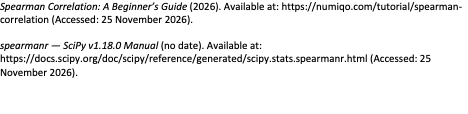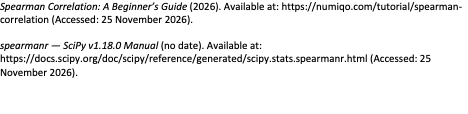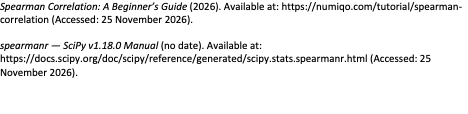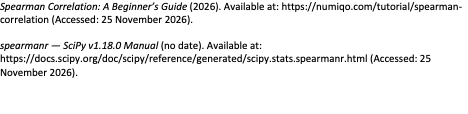Spearman Correlation: A Beginner’s Guide (2026). Available at: https://numiqo.com/tutorial/spearman-correlation (Accessed: 25 November 2026).
spearmanr — SciPy v1.18.0 Manual (no date). Available at: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html (Accessed: 25 November 2026).

).